# 2. Exploratory analysis

*Series:* [1. Data processing](01_data_processing.ipynb) · **[2. Exploratory analysis](02_exploratory_analysis.ipynb)** · [3. Classification](03_classification.ipynb) · [4. Clustering](04_clustering.ipynb) · [5. Explainability](05_explainability.ipynb)

---

The question here is how much signal the features carry, and which ones carry
it.

Every claim here is reported with an effect size alongside its p-value. With
768 patients almost any difference clears significance, and every feature in
this dataset does, at p < 1e-5. Detectable and large enough to matter are
different statements, and only the second one predicts anything.

In [1]:
import warnings

import numpy as np
import pandas as pd

from pima import eda, plots
from pima.data import FEATURES, TARGET, load_processed

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plots.use_style()

df = load_processed()
base_rate = df[TARGET].mean()
print(f"{len(df)} patients, {df[TARGET].sum()} diabetic ({base_rate:.1%})")

768 patients, 268 diabetic (34.9%)


## Class balance

The imbalance is mild, but it sets the floor that every later accuracy figure
has to be read against: a model that predicts "no diabetes" for everyone scores
65.1% while having learned nothing.

In [2]:
counts = df[TARGET].value_counts().rename({0: "no diabetes", 1: "diabetes"})
pd.DataFrame({"n": counts, "share": (counts / len(df)).round(3)})

,n,share
Outcome,,
no diabetes,500,0.651
diabetes,268,0.349


## Distribution shape

In [3]:
eda.distribution_summary(df)

,feature,n,mean,median,sd,min,max,skew,excess_kurtosis
0,Pregnancies,768,3.85,3.00,3.37,0.00,17.00,0.90,0.16
1,Glucose,763,121.69,117.00,30.54,44.00,199.00,0.53,-0.28
2,BloodPressure,733,72.41,72.00,12.38,24.00,122.00,0.13,0.91
3,SkinThickness,541,29.15,29.00,10.48,7.00,99.00,0.69,2.94
4,Insulin,394,155.55,125.00,118.78,14.00,846.00,2.17,6.37
5,BMI,757,32.46,32.30,6.92,18.20,67.10,0.59,0.86
6,DiabetesPedigreeFunction,768,0.47,0.37,0.33,0.08,2.42,1.92,5.59
7,Age,768,33.24,29.00,11.76,21.00,81.00,1.13,0.64


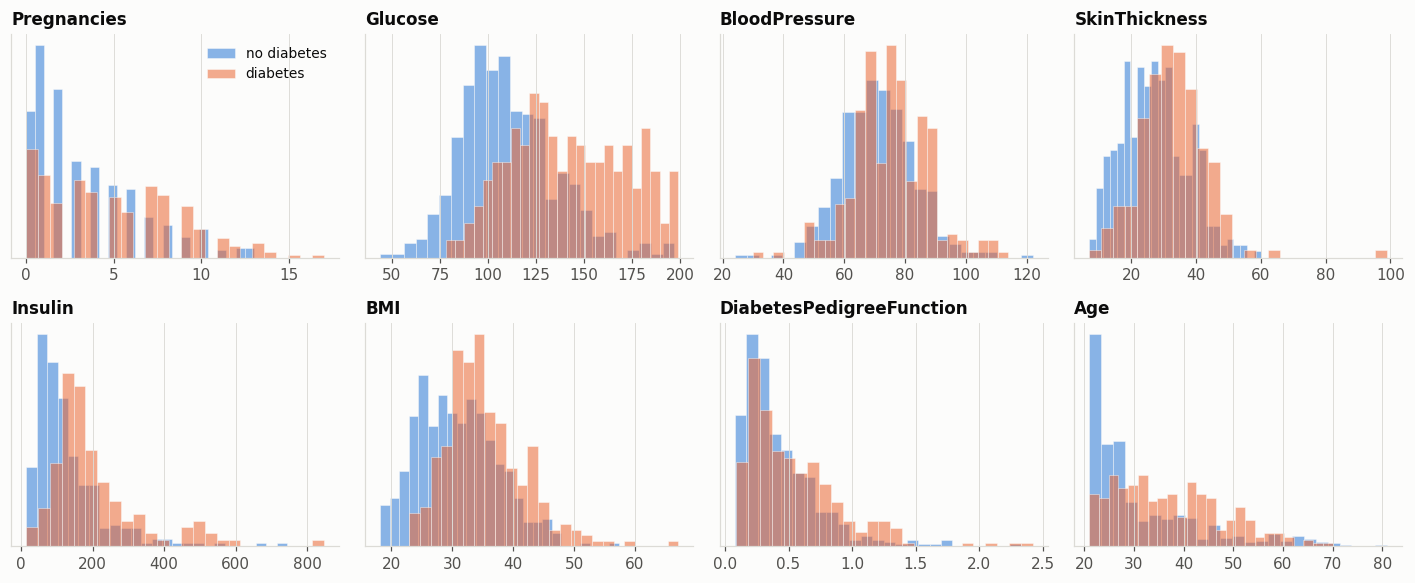

In [4]:
plots.feature_distributions(df, FEATURES);

`Glucose` is the one feature with visible separation between outcome groups,
and even there the distributions overlap across most of their range. `BMI`,
`Age` and `Pregnancies` shift modestly. `BloodPressure` and `SkinThickness` are
nearly identical between groups.

This overlap sets the ceiling on predictive performance. No model can separate
classes that occupy the same space, so whatever gets fitted later is working
against the limit visible here. If several different model families end up
scoring much the same, this picture is where to look for the reason.

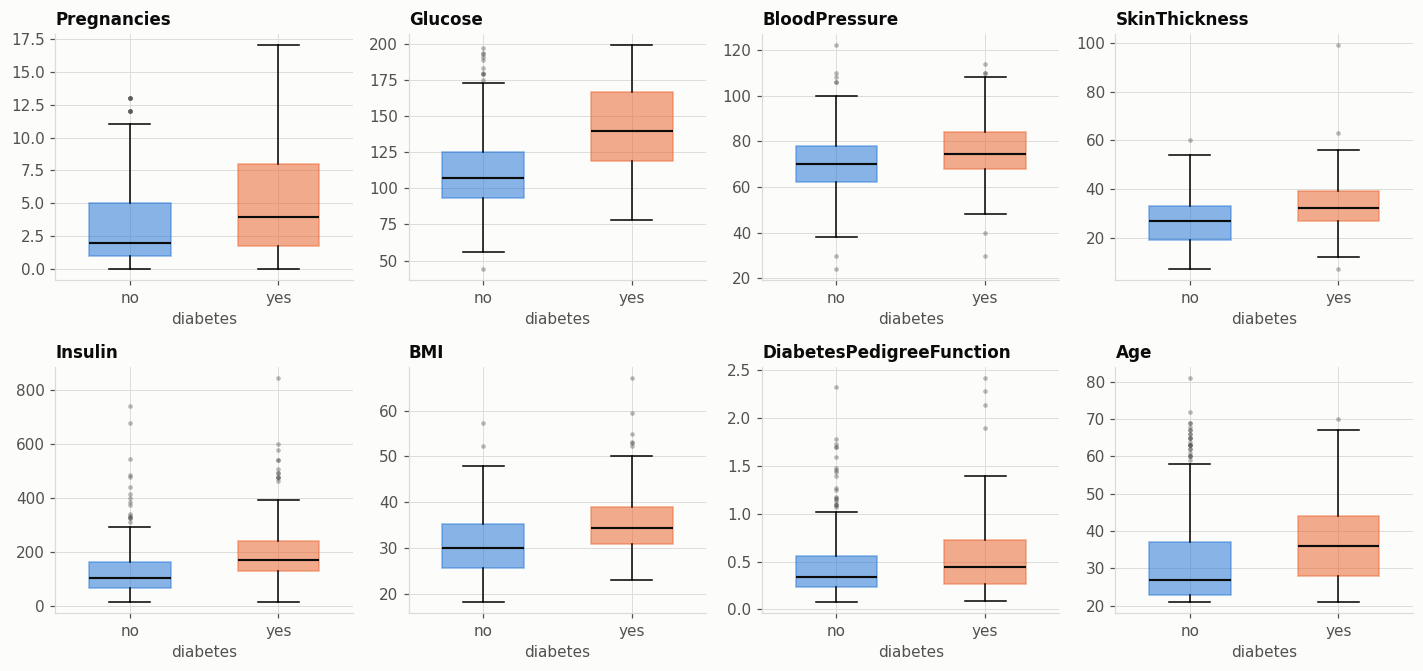

In [5]:
plots.boxplots_by_outcome(df, FEATURES);

The boxes make the skew explicit. `Insulin` and `DiabetesPedigreeFunction` have
long right tails in both groups. The diabetic group sits higher on nearly every
feature, though the interquartile ranges overlap heavily throughout.

## Outliers

In [6]:
outliers = eda.outlier_summary(df)
print(f"rows with at least one outlier: {outliers.attrs['rows_with_any_outlier']} "
      f"({outliers.attrs['pct_rows_with_any_outlier']}% of the cohort)")
outliers

rows with at least one outlier: 84 (10.9% of the cohort)


,feature,lower_fence,upper_fence,n_outliers,pct
0,DiabetesPedigreeFunction,-0.33,1.20,29,3.8
1,Insulin,-94.38,360.62,24,3.1
2,BloodPressure,40.00,104.00,14,1.8
3,Age,-1.50,66.50,9,1.2
4,BMI,13.85,50.25,8,1.0
5,Pregnancies,-6.50,13.50,4,0.5
6,SkinThickness,1.00,57.00,3,0.4
7,Glucose,36.00,204.00,0,0.0


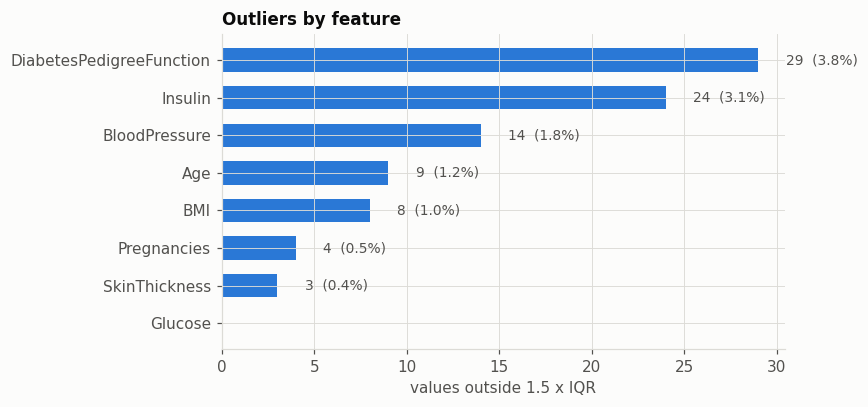

In [7]:
plots.outlier_counts(outliers);

84 patients, 10.9% of the cohort, carry at least one value outside the Tukey
fences, concentrated in `DiabetesPedigreeFunction` (29) and `Insulin` (24).

None of them are removed. The IQR rule flags skew as readily as it flags
error, and every one of these distributions is right-skewed. A patient with a serum insulin of 846 is more plausibly
hyperinsulinaemic, which is the kind of patient this analysis exists to
identify, than mistyped. Deleting these rows would tidy the summary statistics
and throw away signal.

They are handled during modelling instead: standardisation for the
scale-sensitive models, and tree ensembles that are indifferent to monotone
outliers.

## Differences between the outcome groups

Cohen's d is the standardised mean difference: 0.2 small, 0.5 moderate, 0.8
large. The Mann-Whitney U test is used in place of a t-test because several of
these distributions are strongly skewed.

In [8]:
comparison = eda.group_comparison(df)
comparison

,feature,mean_no_diabetes,mean_diabetes,cohens_d,rank_biserial,mannwhitney_p
0,Glucose,110.64,142.32,1.193,-0.586,1.310000e-40
1,BMI,30.86,35.41,0.691,-0.374,1.820000e-17
2,Insulin,130.29,206.85,0.676,-0.463,7.480000e-14
3,SkinThickness,27.24,33.00,0.569,-0.325,6.960000e-10
4,Age,31.19,37.07,0.514,-0.374,1.140000e-17
5,Pregnancies,3.30,4.87,0.477,-0.239,3.750000e-08
6,DiabetesPedigreeFunction,0.43,0.55,0.370,-0.212,1.200000e-06
7,BloodPressure,70.88,75.32,0.364,-0.215,1.630000e-06


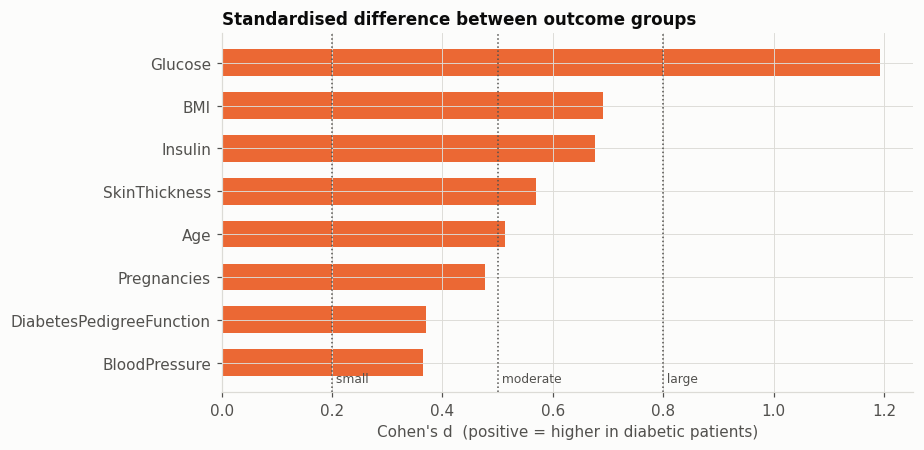

In [9]:
plots.effect_sizes(comparison);

Every feature is statistically significant and only one has a large effect.

The p-values run from 1.3e-40 down to 1.6e-6, so all eight would be reported as
highly significant. The effect sizes are more discriminating: `Glucose` at
d = 1.19 is large and well clear of the rest; `BMI` (0.69) and `Insulin` (0.68)
are moderate; `BloodPressure` (0.36) and `DiabetesPedigreeFunction` (0.37) are
small despite p-values under 1e-5.

With 768 patients, significance measures sample size as much as it measures
difference, which is why the effect sizes are the more useful column here.

One caution on `Glucose`, which applies everywhere it appears later: elevated
blood glucose is close to the diagnostic criterion for diabetes, so its
dominance is substantially definitional and not a discovery about risk.

## Does the relationship hold across the range?

An effect size compares two group means. It cannot say whether a feature rises
steadily with risk, stays flat until some threshold, or only matters at the
extremes, and those cases call for different models.

In [10]:
prevalence = {f: eda.binned_prevalence(df, f, bins=6) for f in FEATURES}
prevalence["Glucose"]

,bin,n,diabetes_rate,midpoint
0,"(43.999, 92.0]",128,0.062,67.9995
1,"(92.0, 105.0]",131,0.168,98.5000
2,"(105.0, 117.0]",127,0.252,111.0000
3,"(117.0, 130.0]",126,0.357,123.5000
4,"(130.0, 154.0]",129,0.473,142.0000
5,"(154.0, 199.0]",122,0.803,176.5000


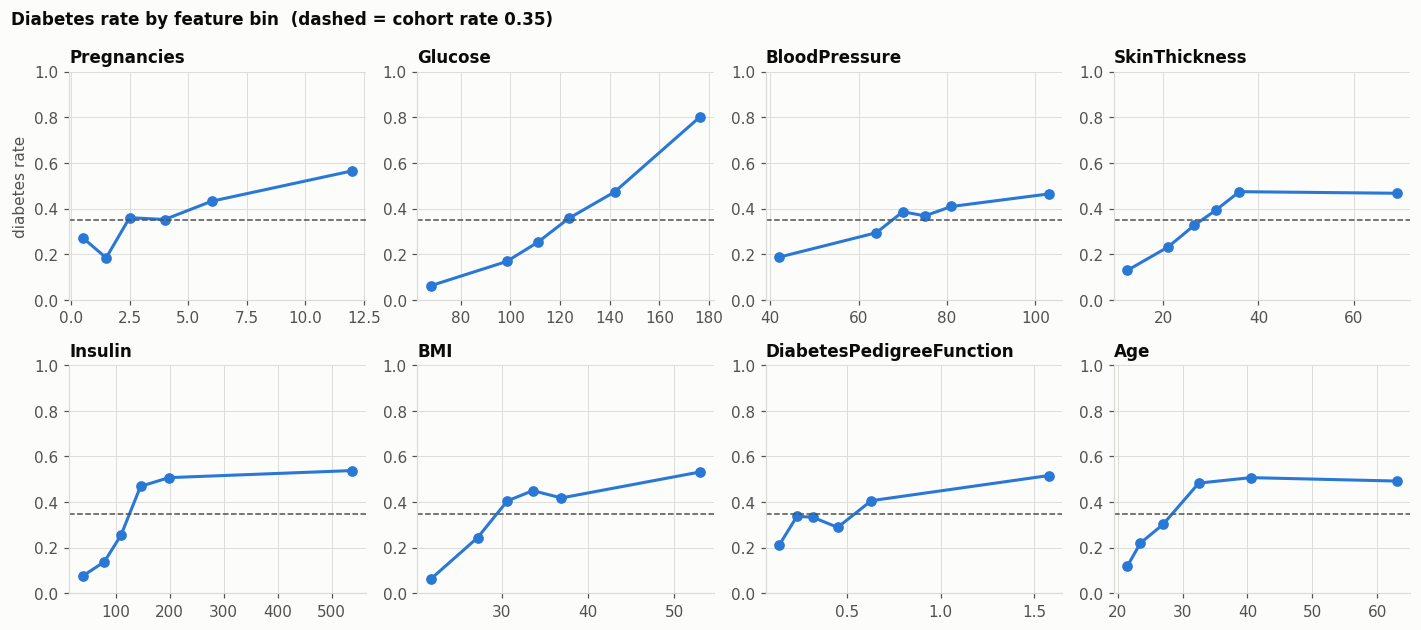

In [11]:
plots.prevalence_curves(prevalence, base_rate);

`Glucose` rises monotonically from 6.2% diabetic in the lowest sixth to 80.3%
in the highest, a thirteen-fold spread, and close enough to a straight line that
a linear model should capture nearly all of it. That curve anticipates notebook
3's result that flexible models gain nothing over logistic regression.

`BMI`, `Age` and `Pregnancies` rise and then flatten or fall at the top bin.
That is mildly non-linear, though on bins small enough that the noise is
comparable to the effect. `BloodPressure` and `SkinThickness` are close to flat,
consistent with their small effect sizes.

## Correlations

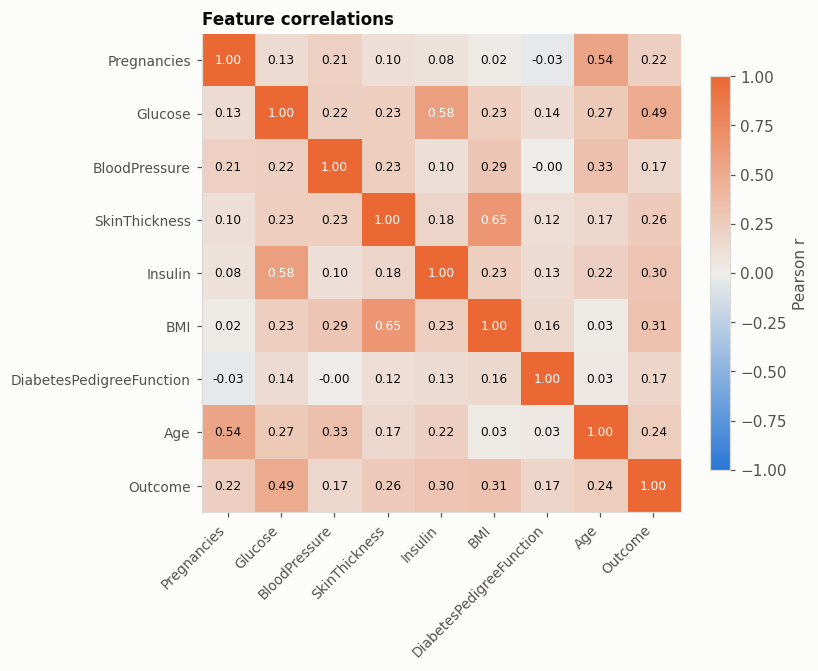

In [12]:
plots.correlation_heatmap(df);

No pair of predictors is collinear enough to destabilise a regression. The
strongest relationships are structural ones: `Age`/`Pregnancies`,
`SkinThickness`/`BMI`, `Glucose`/`Insulin`.

The mild correlations still matter for interpretation later. When `Age` and
`Pregnancies` carry overlapping information, a model can lean on either one and
reach the same accuracy, which would make any single model's feature ranking
less definitive than it looks. Worth remembering once something starts assigning
importance to one of them.

---
## Summary

- The classes overlap heavily, which is what sets the performance ceiling.
- `Glucose` is the only large effect (d = 1.19), rising monotonically from 6.2%
  to 80.3% prevalence across its range, and it is close to definitional.
- All eight features are statistically significant and five have small to
  moderate effects, so significance here largely reflects sample size.
- 10.9% of rows carry an outlier, concentrated in the skewed features. They are
  kept and handled by scaling and model choice.
- The signal is mostly linear, which predicts that flexible models will not
  beat a regularised linear one. That is the next notebook's first test.

Next: [3. Classification](03_classification.ipynb).